# Assignment 5 — Pricing the maximum of two stocks
**Student ID: 83019cd · Group 2 · 20 points**

The contract pays $\max(S_1(T),S_2(T))$ at maturity, with $S_1(0)=S_2(0)=100$, independent stock processes and equal volatility.

We derive an analytic price and the two-stock PDE, solve that PDE with a full two-dimensional finite difference grid, and compare with exact-terminal Monte Carlo. The brief does not specify volatility, maturity or rate; the main example uses $\sigma=20\%$, $T=1$ year and $r=5\%$. Additional examples vary these parameters. No dividends are assumed, consistent with the course BSM framework.

## Course references and implementation
- `Lectures/2026_fall_BME/01_Stochastic_calculus/Stochastic caclulus -  jupyter fall 2026.ipynb`: independent Brownian motions, Itô's lemma and GBM.
- `Lectures/2026_fall_BME/03_bsm/presentation_03_option_basics_and_bsm_model_2026.ipynb`: replication, risk-neutral valuation and Black–Scholes.
- `Lectures/2026_spring_ELTE/07_part1_Finite_method_intro/Finite_difference_method_intro_SOLUTION.ipynb`: finite difference stencils, implicit/CN methods and the same two-stock project in the final project section. The older slide's point count is superseded by the assignment brief's 20 points.
- `Lectures/2026_spring_ELTE/07_part2_BSPDE/Lesson7_solution.ipynb` and `src/numerical_method.py`: one-stock PDE grids and terminal/boundary conditions.
- `Lectures/2026_spring_ELTE/09_Monte_Carlo/08_monte_carlo.ipynb`: exact GBM sampling, discounted sample means and confidence intervals.

`two_stock.py` implements this assignment separately. The two-dimensional sparse operator, boundary treatment and time stepping are new code informed by those lecture concepts. The repository's single-stock market CSVs are not needed: the exercise specifies two stocks starting at 100 with a common constant volatility.

In [1]:
%matplotlib inline
from pathlib import Path
import sys
import importlib
root = Path.cwd().resolve()
while not (root / 'src').is_dir():
    if root == root.parent:
        raise RuntimeError('Run inside the QuantCourseBP repository')
    root = root.parent
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
pricing = importlib.import_module('homeworks.83019cd.assignment_5.two_stock')
analytic_price = pricing.analytic_price
finite_difference_price = pricing.finite_difference_price
monte_carlo_price = pricing.monte_carlo_price
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm
output = root / 'homeworks/83019cd/assignment_5'
figures = output / 'figures'
figures.mkdir(exist_ok=True)
plt.rcParams.update({'figure.dpi':110, 'axes.grid':True, 'grid.alpha':.25})
parameters = dict(spot1=100., spot2=100., volatility=.2, maturity=1., rate=.05)
parameters

{'spot1': 100.0,
 'spot2': 100.0,
 'volatility': 0.2,
 'maturity': 1.0,
 'rate': 0.05}

## (a) Analytic fair value
Under the risk-neutral measure, for independent Brownian motions,
$$dS_i=rS_i\,dt+\sigma S_i\,dW_i,\qquad dW_1dW_2=0.$$
Let $\tau=T-t$. Risk-neutral valuation gives
$$V=e^{-r\tau}\mathbb E^{\mathbb Q}[\max(S_1(T),S_2(T))\mid S_1,S_2].$$
The payoff is homogeneous of degree one. We can also write
$$\max(S_1,S_2)=S_2+(S_1-S_2)^+,$$
so the contract is one stock plus an exchange option.

To derive the closed form directly, let independent $Z_i\sim N(0,1)$ and $a=\sigma\sqrt\tau$. Then
$$e^{-r\tau}S_i(T)=S_i e^{-a^2/2+aZ_i}.$$
The first stock wins when
$$Z_1-Z_2> -\frac{\log(S_1/S_2)}a.$$
In the expectation weighted by $e^{-a^2/2+aZ_1}$, completing the square shifts $Z_1$'s normal mean from 0 to $a$. The difference $Z_1-Z_2$ then has mean $a$ and variance 2. Thus the first stock's discounted contribution is
$$S_1\Phi\left(\frac{\log(S_1/S_2)+\sigma^2\tau}{\sigma\sqrt{2\tau}}\right).$$
Swapping the stock indices gives the second contribution. Define $\nu=\sqrt2\sigma$:
$$\boxed{V=S_1\Phi(d_1)+S_2\Phi(d_2)},$$
$$d_1=\frac{\log(S_1/S_2)+\nu^2\tau/2}{\nu\sqrt\tau},\qquad
 d_2=\frac{\log(S_2/S_1)+\nu^2\tau/2}{\nu\sqrt\tau}.$$
Here $d_2$ is the second stock's winning contribution argument, not the usual vanilla-call $d_2$.

At equal spots of 100:
$$\boxed{V(0)=200\Phi(\sigma\sqrt{T/2})}.$$
Interest rate cancels because the stocks share the same risk-neutral drift and the payoff is homogeneous. This relies on no dividends; independence alone does not imply rate independence for arbitrary payoffs. At zero volatility or zero remaining time the price is $\max(S_1,S_2)$.

In [2]:
exact = analytic_price(**parameters)
print(f'Analytic fair value: {exact:.10f}')
print(f'Equal-spot formula: {200*norm.cdf(.2/np.sqrt(2)):.10f}')
print(f'Premium over holding one stock: {exact-100:.10f}')

Analytic fair value: 111.2462916018
Equal-spot formula: 111.2462916018
Premium over holding one stock: 11.2462916018


## (b) Deriving the PDE
For $V(t,S_1,S_2)$, multivariate Itô's lemma gives
$$dV=\left[V_t+rS_1V_{S_1}+rS_2V_{S_2}
+\tfrac12\sigma^2S_1^2V_{S_1S_1}+\tfrac12\sigma^2S_2^2V_{S_2S_2}\right]dt
+\sigma S_1V_{S_1}dW_1+\sigma S_2V_{S_2}dW_2.$$
There is no mixed term because $dW_1dW_2=0$. In a correlated model that term would be $\rho\sigma^2S_1S_2V_{S_1S_2}$.

Hold $V_{S_1}$ units of stock 1 and $V_{S_2}$ units of stock 2 to remove the random terms locally. Equating the hedged portfolio's drift to its risk-free return yields
$$\boxed{V_t+\tfrac12\sigma^2(S_1^2V_{S_1S_1}+S_2^2V_{S_2S_2})
+r(S_1V_{S_1}+S_2V_{S_2})-rV=0}.$$
Terminal condition:
$$V(T,S_1,S_2)=\max(S_1,S_2).$$
On the axes, $V(t,0,S_2)=S_2$ and $V(t,S_1,0)=S_1$; at the origin $V=0$. When one stock dominates the other, $V\sim\max(S_1,S_2)$.

### Log coordinates
Use $x=\log(S_1/S_{1,0})$, $y=\log(S_2/S_{2,0})$, $\tau=T-t$, and $u(\tau,x,y)=V$:
$$u_\tau=\tfrac12\sigma^2(u_{xx}+u_{yy})
+(r-\tfrac12\sigma^2)(u_x+u_y)-ru.$$
This follows from $S_iV_{S_i}=u_{x_i}$ and $S_i^2V_{S_iS_i}=u_{x_ix_i}-u_{x_i}$.

The infinite spatial domain is truncated to $[-L,L]^2$. Initial data at $\tau=0$ are $\max(S_{1,0}e^x,S_{2,0}e^y)$. At the artificial outer edges we use the dominant-stock approximation $u=\max(S_1,S_2)$. **This boundary is approximate**, particularly near equal-stock corners. Domain expansion at fixed mesh spacing below checks its effect on the requested central price. We do not impose the analytic formula on the boundaries.

## (c) Full two-dimensional finite difference solution
At grid spacing $h$, use central differences in each spatial direction:
$$u_x\approx\frac{u_{i+1,j}-u_{i-1,j}}{2h},\qquad
u_{xx}\approx\frac{u_{i+1,j}-2u_{i,j}+u_{i-1,j}}{h^2},$$
and the same stencils in $y$. Write $D=\sigma^2/2$ and $\mu=r-\sigma^2/2$. Each direction has lower coefficient $D/h^2-\mu/(2h)$, diagonal $-2D/h^2$, and upper coefficient $D/h^2+\mu/(2h)$.

After flattening interior nodes, the ODE system is
$$\frac{d\mathbf u}{d\tau}=A\mathbf u+\mathbf b,\qquad
A=L_x\otimes I+I\otimes L_y-rI,$$
where $\mathbf b$ collects fixed Dirichlet edge values. Crank–Nicolson advances using
$$\left(I-\tfrac12\Delta\tau A\right)\mathbf u^{n+1}
=\left(I+\tfrac12\Delta\tau A\right)\mathbf u^n+\Delta\tau\mathbf b.$$
The terminal payoff has a kink along $S_1=S_2$. Replace the first full CN step with two backward-Euler half steps (Rannacher smoothing), then continue with CN. Reuse a sparse LU factorization; no explicit matrix inverse is computed.

We require nonnegative off-diagonal drift/diffusion coefficients; the code asks for spatial refinement when this monotonicity condition fails. CN is stable for this dissipative operator but does not guarantee positivity for arbitrarily large time steps. The chosen time grids are checked by time refinement. Even spatial step counts put the requested price exactly on a node, avoiding interpolation error.

In [3]:
space_rows = []
for n in [20,40,80,120,160,240]:
    result = finite_difference_price(**parameters,space_steps=n,time_steps=400,log_half_width=1.5)
    space_rows.append({'space_steps':n, 'interior_unknowns':(n-1)**2,
                       'log_spacing':3/n, 'time_steps':400, 'price':result.price,
                       'absolute_error':abs(result.price-exact), 'runtime_seconds':result.runtime_seconds})
space = pd.DataFrame(space_rows)
space['observed_order'] = np.nan
for i in range(1,len(space)):
    space.loc[i,'observed_order'] = np.log(space.loc[i-1,'absolute_error']/space.loc[i,'absolute_error'])/np.log(space.loc[i,'space_steps']/space.loc[i-1,'space_steps'])
space.to_csv(output/'spatial_convergence.csv',index=False)
space

,space_steps,interior_unknowns,log_spacing,time_steps,price,absolute_error,runtime_seconds,observed_order
0,20,361,0.15000,400,110.911786,0.334505,0.009308,NaN
1,40,1521,0.07500,400,111.167423,0.078869,0.027007,2.084500
2,80,6241,0.03750,400,111.226803,0.019488,0.119992,2.016851
3,120,14161,0.02500,400,111.237647,0.008645,0.348714,2.004830
4,160,25281,0.01875,400,111.241432,0.004860,0.611062,2.001838
5,240,57121,0.01250,400,111.244131,0.002160,1.584475,1.999861


In [4]:
time_rows = []
for steps in [10,20,40,80,160,320]:
    result = finite_difference_price(**parameters,space_steps=120,time_steps=steps,log_half_width=1.5)
    time_rows.append({'time_steps':steps, 'price':result.price, 'analytic_error':abs(result.price-exact),
                     'runtime_seconds':result.runtime_seconds})
time_results = pd.DataFrame(time_rows)
time_results['difference_from_finest_time'] = abs(time_results.price-time_results.price.iloc[-1])
time_results.to_csv(output/'time_convergence.csv',index=False)
domain_rows = []
# Keep h=0.03 while expanding L: this separates boundary and mesh effects.
for width in [.3,.6,.9,1.2,1.5,1.8]:
    n = int(round(2*width/.03))
    result = finite_difference_price(**parameters,space_steps=n,time_steps=200,log_half_width=width)
    domain_rows.append({'log_half_width':width, 'space_steps':n, 'log_spacing':2*width/n,
                        'price':result.price, 'analytic_error':abs(result.price-exact)})
domain = pd.DataFrame(domain_rows)
domain['difference_from_widest_domain'] = abs(domain.price-domain.price.iloc[-1])
domain.to_csv(output/'domain_convergence.csv',index=False)
display(time_results)
display(domain)

,time_steps,price,analytic_error,runtime_seconds,difference_from_finest_time
0,10,111.234758,0.011534,0.031005,0.002888
1,20,111.236760,0.009532,0.037913,0.000886
2,40,111.237425,0.008866,0.051155,0.000221
3,80,111.237593,0.008698,0.079033,0.000053
4,160,111.237635,0.008656,0.133349,0.000011
5,320,111.237646,0.008646,0.245051,0.000000


,log_half_width,space_steps,log_spacing,price,analytic_error,difference_from_widest_domain
0,0.3,20,0.03,110.850517,0.395775,3.833119e-01
1,0.6,40,0.03,111.233552,0.012739,2.761933e-04
2,0.9,60,0.03,111.233829,0.012463,1.091382e-08
3,1.2,80,0.03,111.233829,0.012463,3.126388e-13
4,1.5,100,0.03,111.233829,0.012463,3.453238e-12
5,1.8,120,0.03,111.233829,0.012463,0.000000e+00


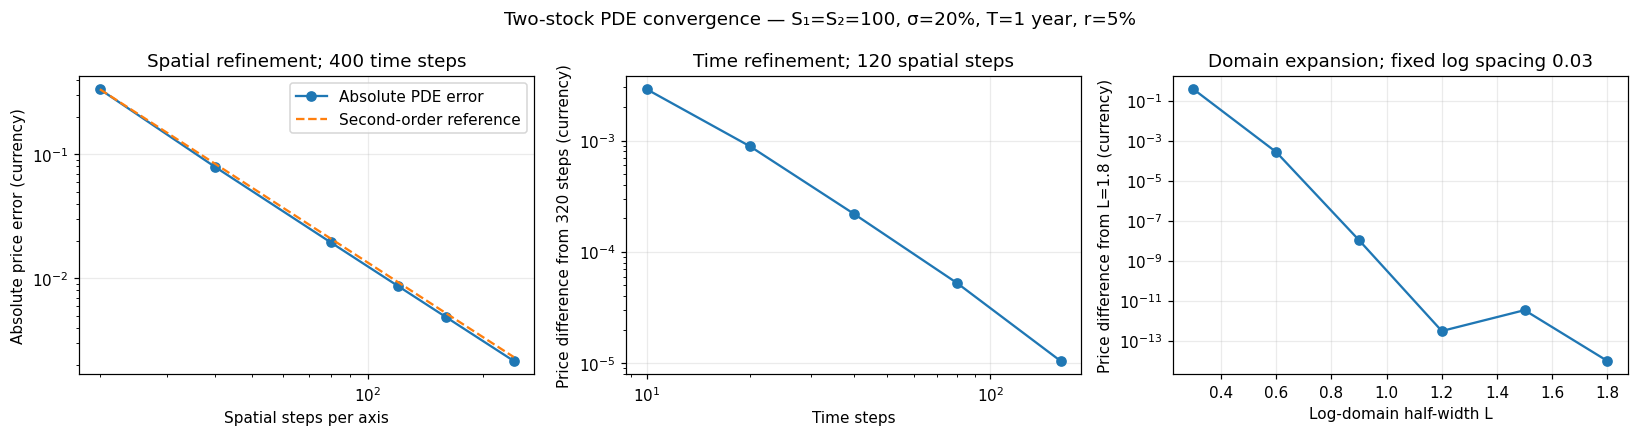

Domain errors below 1e-14 are clipped for logarithmic plotting.


In [5]:
fig, axes = plt.subplots(1,3,figsize=(15,4))
axes[0].loglog(space.space_steps,space.absolute_error,'o-',label='Absolute PDE error')
reference = space.absolute_error.iloc[0]*(space.space_steps.iloc[0]/space.space_steps)**2
axes[0].loglog(space.space_steps,reference,'--',label='Second-order reference')
axes[0].set(title='Spatial refinement; 400 time steps',xlabel='Spatial steps per axis',ylabel='Absolute price error (currency)')
axes[0].legend()
axes[1].loglog(time_results.time_steps[:-1],np.maximum(time_results.difference_from_finest_time[:-1],1e-14),'o-')
axes[1].set(title='Time refinement; 120 spatial steps',xlabel='Time steps',ylabel='Price difference from 320 steps (currency)')
axes[2].semilogy(domain.log_half_width,np.maximum(domain.difference_from_widest_domain,1e-14),'o-')
axes[2].set(title='Domain expansion; fixed log spacing 0.03',xlabel='Log-domain half-width L',ylabel='Price difference from L=1.8 (currency)')
fig.suptitle('Two-stock PDE convergence — S₁=S₂=100, σ=20%, T=1 year, r=5%')
fig.tight_layout();fig.savefig(figures/'pde_convergence.png',bbox_inches='tight');plt.show()
print('Domain errors below 1e-14 are clipped for logarithmic plotting.')

Spatial refinement should show approximately second-order convergence in the central price. Time refinement isolates the time integration error by comparing with the finest time grid **at the same spatial resolution**; the remaining analytic error includes spatial error. The domain-expansion result approaches a plateau in analytic error because the spatial spacing remains fixed. Agreement between large domains checks the central price, not accuracy everywhere near their artificial edges.

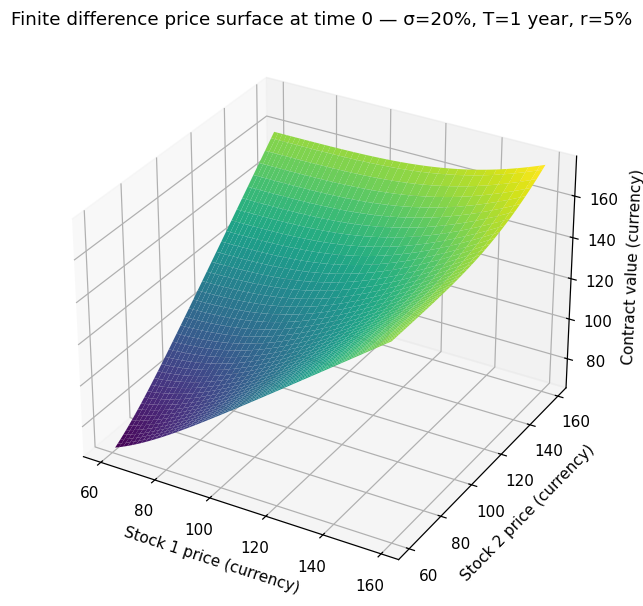

Finest PDE price: 111.2441314962; analytic error: -0.0021601056


In [6]:
pde = finite_difference_price(**parameters,space_steps=240,time_steps=400,log_half_width=1.5)
# Display only the central region to avoid presenting artificial edge values as exact.
mask1 = (pde.spot1_grid>=60)&(pde.spot1_grid<=160)
mask2 = (pde.spot2_grid>=60)&(pde.spot2_grid<=160)
x,y = np.meshgrid(pde.spot1_grid[mask1],pde.spot2_grid[mask2],indexing='ij')
fig = plt.figure(figsize=(10,6));ax=fig.add_subplot(111,projection='3d')
ax.plot_surface(x,y,pde.values[np.ix_(mask1,mask2)],cmap='viridis',linewidth=0)
ax.set(xlabel='Stock 1 price (currency)',ylabel='Stock 2 price (currency)',zlabel='Contract value (currency)',
       title='Finite difference price surface at time 0 — σ=20%, T=1 year, r=5%')
fig.subplots_adjust(left=0, right=.82, bottom=.05, top=.9)
fig.savefig(figures/'pde_surface.png', pad_inches=.3);plt.show()
print(f'Finest PDE price: {pde.price:.10f}; analytic error: {pde.price-exact:+.10f}')

## (d) Monte Carlo comparison
For each independent simulation draw two independent standard normals:
$$S_i(T)=S_i(0)\exp\left((r-\sigma^2/2)T+\sigma\sqrt T Z_i\right),\quad i=1,2.$$
Sample discounted payoff $X=e^{-rT}\max(S_1(T),S_2(T))$, estimate $\hat V=\bar X$, and calculate
$$\operatorname{SE}(\hat V)=\frac{s_X}{\sqrt N},\qquad
\text{approximate 95\% CI}=\hat V\pm1.96\operatorname{SE}(\hat V).$$
Because of homogeneity, discounting can be combined with the terminal exponential: $X=\max_i S_i(0)e^{-\sigma^2T/2+\sigma\sqrt T Z_i}$. The code uses this equivalent form. This also explains rate independence path by path when the same normal draws are used.

Exact terminal sampling avoids time discretization error; no paths between 0 and T are needed. The stock shocks are independent. The sample variance uses `ddof=1`; no correlated antithetic samples or fitted control variates complicate the standard error. A fixed seed makes runs reproducible. The CLT confidence interval is approximate, and 95% intervals need not cover the exact price on every run.

In [7]:
mc_rows = []
for n in [1_000,10_000,100_000,1_000_000]:
    mc = monte_carlo_price(**parameters,num_paths=n,seed=2026)
    mc_rows.append({'num_paths':n,'price':mc.price,'standard_error':mc.standard_error,
                    'ci_low':mc.ci_low,'ci_high':mc.ci_high,'absolute_error':abs(mc.price-exact),
                    'runtime_seconds':mc.runtime_seconds})
mc_results = pd.DataFrame(mc_rows)
mc_results.to_csv(output/'monte_carlo_convergence.csv',index=False)
mc_results

,num_paths,price,standard_error,ci_low,ci_high,absolute_error,runtime_seconds
0,1000,110.569340,0.592511,109.408019,111.730661,0.676952,0.000410
1,10000,111.324588,0.187588,110.956915,111.692261,0.078297,0.000464
2,100000,111.252183,0.059016,111.136512,111.367854,0.005892,0.004066
3,1000000,111.254514,0.018712,111.217838,111.291189,0.008222,0.042022


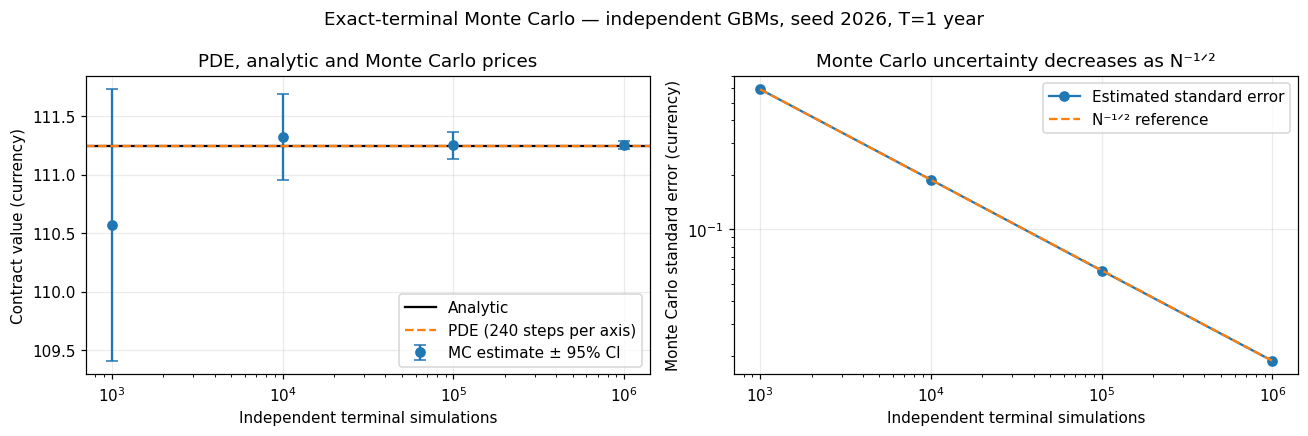

Analytic: 111.24629160
PDE:      111.24413150 (error -0.00216011)
MC:       111.25451376; SE 0.01871210
95% CI:   [111.21783803, 111.29118948]


In [8]:
fig,axes=plt.subplots(1,2,figsize=(12,4))
axes[0].errorbar(mc_results.num_paths,mc_results.price,yerr=1.96*mc_results.standard_error,fmt='o',capsize=4,label='MC estimate ± 95% CI')
axes[0].axhline(exact,color='black',label='Analytic')
axes[0].axhline(pde.price,color='tab:orange',linestyle='--',label='PDE (240 steps per axis)')
axes[0].set(xscale='log',xlabel='Independent terminal simulations',ylabel='Contract value (currency)',title='PDE, analytic and Monte Carlo prices')
axes[0].legend()
axes[1].loglog(mc_results.num_paths,mc_results.standard_error,'o-',label='Estimated standard error')
axes[1].loglog(mc_results.num_paths,mc_results.standard_error.iloc[0]*np.sqrt(mc_results.num_paths.iloc[0]/mc_results.num_paths),'--',label='N⁻¹ᐟ² reference')
axes[1].set(xlabel='Independent terminal simulations',ylabel='Monte Carlo standard error (currency)',title='Monte Carlo uncertainty decreases as N⁻¹ᐟ²')
axes[1].legend()
fig.suptitle('Exact-terminal Monte Carlo — independent GBMs, seed 2026, T=1 year')
fig.tight_layout();fig.savefig(figures/'mc_comparison.png',bbox_inches='tight');plt.show()
last=mc_results.iloc[-1]
print(f"Analytic: {exact:.8f}")
print(f"PDE:      {pde.price:.8f} (error {pde.price-exact:+.8f})")
print(f"MC:       {last.price:.8f}; SE {last.standard_error:.8f}")
print(f"95% CI:   [{last.ci_low:.8f}, {last.ci_high:.8f}]")

## Additional parameters and sanity checks
The equal initial spots and equal volatilities are the assigned case. Unequal initial spots below are supplementary symmetry and robustness checks of the general formula and solver. We keep a wide log domain and refine the mesh for these cases. The analytic value is independent of rate; a finite PDE grid has residual numerical rate dependence, which should shrink with refinement.

In [9]:
case_rows=[]
for s1,s2,vol,tau,rate in [(100,100,.15,.5,.03),(100,100,.3,2.,.05),(80,120,.2,1.,.05),(120,80,.2,1.,.05),(100,100,.2,1.,0.),(100,100,.2,1.,.1)]:
    kwargs=dict(spot1=s1,spot2=s2,volatility=vol,maturity=tau,rate=rate)
    a=analytic_price(**kwargs)
    fd=finite_difference_price(**kwargs,space_steps=200,time_steps=400,log_half_width=2.)
    mc=monte_carlo_price(**kwargs,num_paths=200_000,seed=2026)
    case_rows.append(dict(**kwargs,analytic=a,pde=fd.price,pde_error=fd.price-a,
                          mc=mc.price,mc_se=mc.standard_error,mc_z_score=(mc.price-a)/mc.standard_error))
cases=pd.DataFrame(case_rows);cases.to_csv(output/'parameter_comparison.csv',index=False)
cases

,spot1,spot2,volatility,maturity,rate,analytic,pde,pde_error,mc,mc_se,mc_z_score
0,100,100,0.15,0.5,0.03,105.978529,105.965981,-0.012548,105.989993,0.020911,0.548253
1,100,100,0.30,2.0,0.05,123.582284,123.580348,-0.001936,123.629551,0.102552,0.460901
2,80,120,0.20,1.0,0.05,120.936721,120.938596,0.001875,120.990655,0.052331,1.030646
3,120,80,0.20,1.0,0.05,120.936721,120.938596,0.001875,120.924582,0.052417,-0.231574
4,100,100,0.20,1.0,0.00,111.246292,111.238994,-0.007298,111.268196,0.041836,0.523579
5,100,100,0.20,1.0,0.10,111.246292,111.242530,-0.003762,111.268196,0.041836,0.523579


## Findings and limitations
- The analytic benchmark is about **111.24629**, larger than either initial stock price: the holder benefits from receiving whichever stock wins. The value lies between `max(S1,S2)` and `S1+S2`.
- The full two-dimensional PDE converges toward the formula under spatial refinement. Domain checks are essential because the outer boundary is an approximation. Time-step refinement distinguishes time error from spatial error.
- The Monte Carlo estimate agrees within its sampling uncertainty. Its standard error follows the expected inverse square-root behavior; realized absolute errors need not decrease monotonically as sample size increases.
- The PDE supplies a surface, but costs grow quickly with two spatial dimensions. Monte Carlo is especially simple here because the terminal GBM distribution is known. Recorded runtimes are illustrative single runs, including sparse factorization for PDE and random generation for MC; they are not controlled performance benchmarks.
- None of the numerical routines calls the analytic price. It is used only for comparisons and tests. High volatility or long maturity require a wider domain and adequate resolution. This implementation checks a central-stencil monotonicity condition and rejects inadequate grids rather than silently accepting them.

## Validation
Run from repository root:
```
venv_quant_course_v312/bin/python -m pytest homeworks/83019cd/assignment_5 -q
```
Tests cover an independent numerical integration benchmark, deterministic limits, exchange symmetry, scale homogeneity, price bounds, spatial refinement, artificial boundary sensitivity, Monte Carlo terminal draws and standard errors, fixed-seed agreement and invalid inputs.

The notebook is executed with embedded figures. CSV files store the experiment results and `figures/` stores exported plots. All numerical examples are reproducible from the local code and stated assumptions.